In [ ]:
import pandas as pd
from sqlalchemy import create_engine, text

# 1. Read your CSV file
csv_file = "final_encoded_plant_features.csv"
plant_df = pd.read_csv(csv_file)
print(f"📖 Loaded {len(plant_df)} plants from your CSV file.")

# 🔥 MAP COLUMNS: Ensure 'Number' maps to 'ID' cleanly
if 'Number' in plant_df.columns:
    plant_df = plant_df.rename(columns={'Number': 'ID'})
    print("🆔 Successfully mapped your CSV 'Number' column to database 'ID' column.")
elif 'ID' not in plant_df.columns:
    plant_df.insert(0, 'ID', range(1, len(plant_df) + 1))
    print("🆔 Generated ID column from 1 to 3170.")

# 2. Connect to your phpMyAdmin database
engine = create_engine("mysql+mysqlconnector://root:@localhost/plantmatch_db")
target_table = "plantmatch_ultimate_complete"

# 🔥 NEW: Dynamically build the perfect CREATE TABLE query layout
create_parts = []
for col, dtype in plant_df.dtypes.items():
    col_name = f"`{col}`"
    if col == 'ID':
        create_parts.append(f"{col_name} INT PRIMARY KEY") 
    elif col == 'Image_URL':
        create_parts.append(f"{col_name} LONGTEXT")        
    elif 'float' in str(dtype):
        create_parts.append(f"{col_name} FLOAT(53)")
    elif 'int' in str(dtype):
        create_parts.append(f"{col_name} BIGINT")
    else:
        create_parts.append(f"{col_name} TEXT")

create_table_sql = f"CREATE TABLE {target_table} (\n\t" + ",\n\t".join(create_parts) + "\n);"

# 3. Safe Execution Session
try:
    with engine.begin() as conn:
        print("🔓 Temporarily disabling foreign key constraint guardrails...")
        conn.execute(text("SET FOREIGN_KEY_CHECKS = 0;"))
        
        print(f"🗑️ Safely dropping old table layout if it exists...")
        conn.execute(text(f"DROP TABLE IF EXISTS {target_table};"))
        
        print(f"🏗️ Building new table with Primary Key predefined...")
        conn.execute(text(create_table_sql))
        
        print(f"🚀 Pushing data rows to '{target_table}' in fast chunks...")
        # Use 'append' now since our custom query already set up the perfect structural layout!
        # Pushing data rows to 'plantmatch_ultimate_complete' in fast chunks...
        plant_df.to_sql(
            name=target_table,
            con=conn,          
            if_exists='append', 
            index=False,
            chunksize=50,       
            method='multi'
        )
        
        print("🔒 Reactivating foreign key constraints...")
        conn.execute(text("SET FOREIGN_KEY_CHECKS = 1;"))
        
    print("\n🎉 SUCCESS! Your live database table is now 100% populated with matching types and active constraints!")

except Exception as e:
    print(f"❌ Upload failed: {e}")

📖 Loaded 3170 plants from your CSV file.
🔓 Temporarily disabling foreign key constraint guardrails...
🗑️ Safely dropping old table layout if it exists...
🏗️ Building new table with Primary Key predefined...
🚀 Pushing data rows to 'plantmatch_ultimate_complete' in fast chunks...
🔒 Reactivating foreign key constraints...

🎉 SUCCESS! Your live database table is now 100% populated with matching types and active constraints!


In [7]:
from sqlalchemy import create_engine, text

engine = create_engine("mysql+mysqlconnector://root:@localhost/plantmatch_db")

with engine.connect() as conn:
    # Query MySQL directly for a list of all actual live tables
    result = conn.execute(text("SHOW TABLES;"))
    tables = [row[0] for row in result]
    
    print("📋 CURRENT LIVE TABLES IN YOUR DATABASE:")
    print("-" * 40)
    for t in tables:
        print(f"  🔹 {t}")
    print("-" * 40)
    
    if "plantmatch_ultimate_complete" in tables:
        # Check how many rows are actually inside it
        count_res = conn.execute(text("SELECT COUNT(*) FROM plantmatch_ultimate_complete;"))
        row_count = count_res.scalar()
        print(f"✅ FOUND IT! 'plantmatch_ultimate_complete' exists and holds {row_count} rows.")
    else:
        print("❌ Missing: The table is not found under this database name.")

📋 CURRENT LIVE TABLES IN YOUR DATABASE:
----------------------------------------
  🔹 favorite
  🔹 feedback
  🔹 plantmatch_ultimate_complete
  🔹 preference
  🔹 recommendation
  🔹 save
  🔹 users
----------------------------------------
✅ FOUND IT! 'plantmatch_ultimate_complete' exists and holds 3170 rows.


In [8]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

# ==========================================================
# 1. FETCH LIVE DATA FROM BOTH DATABASE TABLES
# ==========================================================
engine = create_engine("mysql+mysqlconnector://root:@localhost/plantmatch_db")

with engine.connect() as conn:
    print("🔌 Connecting to plantmatch_db...")
    feedback_df = pd.read_sql("SELECT userID, plantID, rating FROM feedback", conn)
    plant_df = pd.read_sql("SELECT * FROM plantmatch_ultimate_complete", conn)

print(f"✅ Successfully linked {len(plant_df)} plants and {len(feedback_df)} user feedback records!")

# ==========================================================
# 2. COMPUTE REAL CONTENT-BASED SIMILARITY MATRIX
# ==========================================================
print("🧠 Generating Content Similarity from your pre-encoded features...")

# Isolate only the numerical feature columns for mathematical Cosine Similarity
columns_to_drop = ['ID', 'Scientific_Name', 'Common_Name', 'Image_URL']
feature_matrix = plant_df.drop(columns=columns_to_drop, errors='ignore')

# Compute the plant-to-plant similarity matrix
cosine_sim_array = cosine_similarity(feature_matrix)
content_sim_df = pd.DataFrame(
    cosine_sim_array, 
    index=plant_df["ID"], 
    columns=plant_df["ID"]
)

# ==========================================================
# 3. COMPUTE COLLABORATIVE UTILITY MATRIX GRID
# ==========================================================
utility_matrix = feedback_df.pivot_table(
    index='userID', columns='plantID', values='rating', aggfunc='mean'
).fillna(0.0)

# ==========================================================
# 4. HYBRID BLENDING FUNCTION
# ==========================================================
def get_hybrid_scores(target_user_id, alpha=0.5):
    user_ratings = utility_matrix.loc[target_user_id]
    
    # --- Pipeline A: Content-Based Profile ---
    liked_plants = user_ratings[user_ratings >= 4].index
    # Guardrail: Only use liked plants that exist in our loaded features table
    liked_plants = [p for p in liked_plants if p in content_sim_df.columns]
    
    if len(liked_plants) > 0:
        content_scores = content_sim_df[liked_plants].mean(axis=1)
    else:
        content_scores = pd.Series(0.0, index=plant_df["ID"])
        
    # --- Pipeline B: Collaborative KNN Profile ---
    sparse_features = csr_matrix(utility_matrix.values)
    knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=min(3, len(utility_matrix)))
    knn.fit(sparse_features)
    
    user_idx = utility_matrix.index.get_loc(target_user_id)
    distances, indices = knn.kneighbors(utility_matrix.iloc[user_idx].values.reshape(1, -1))
    
    neighbor_indices = indices.flatten()[1:]
    collab_scores = pd.Series(0.0, index=plant_df["ID"])
    
    for idx in neighbor_indices:
        neighbor_ratings = utility_matrix.iloc[idx]
        for plant_id, rat in neighbor_ratings.items():
            if plant_id in collab_scores.index:
                collab_scores[plant_id] += rat
            
    # Normalize Collaborative ratings to 0.0 - 1.0 scale
    if collab_scores.max() != collab_scores.min():
        collab_scores = (collab_scores - collab_scores.min()) / (collab_scores.max() - collab_scores.min())
        
    content_scores = content_scores.reindex(plant_df["ID"], fill_value=0.0)
    collab_scores = collab_scores.reindex(plant_df["ID"], fill_value=0.0)
    
    # 50/50 Balanced Hybrid Score Blending
    hybrid_scores = (content_scores * alpha) + (collab_scores * (1 - alpha))
    return hybrid_scores

# ==========================================================
# 5. ACCURACY EVALUATION (Precision, Recall, F1-Score)
# ==========================================================
print("📊 Evaluating metrics against real live database connections...")

precisions = []
recalls = []

for user in utility_matrix.index:
    actual_ratings = utility_matrix.loc[user]
    ground_truth_liked = set(actual_ratings[actual_ratings >= 4].index)
    
    if len(ground_truth_liked) == 0:
        continue 
        
    scores = get_hybrid_scores(user)
    
    # Hide items the user has already rated to evaluate predictive discovery
    already_rated = actual_ratings[actual_ratings > 0].index
    scores_filtered = scores.drop(already_rated, errors='ignore')
    
    top_recommendations = set(scores_filtered.sort_values(ascending=False).head(5).index)
    hits = len(top_recommendations.intersection(ground_truth_liked))
    
    precision = hits / 5
    recall = hits / len(ground_truth_liked) if len(ground_truth_liked) > 0 else 0
    
    precisions.append(precision)
    recalls.append(recall)

avg_precision = np.mean(precisions) if precisions else 0.0
avg_recall = np.mean(recalls) if recalls else 0.0
f1_score = 2 * (avg_precision * avg_recall) / (avg_precision + avg_recall) if (avg_precision + avg_recall) > 0 else 0.0

# ==========================================================
# 6. OUTPUT EVALUATION PRESENTATION TABLE
# ==========================================================
metrics_summary = pd.DataFrame({
    "Evaluation Metric": ["Precision @ 5", "Recall @ 5", "F1-Score Summary"],
    "Mathematical Decimal": [round(avg_precision, 4), round(avg_recall, 4), round(f1_score, 4)],
    "Percentage Match": [f"{round(avg_precision * 100, 1)}%", f"{round(avg_recall * 100, 1)}%", f"{round(f1_score * 100, 1)}%"]
})

print("\n========================================================")
print("     REAL HYBRID DATA ENGINE ACCURACY EVALUATION       ")
print("========================================================")
print(metrics_summary.to_string(index=False))
print("========================================================")

🔌 Connecting to plantmatch_db...
✅ Successfully linked 3170 plants and 17 user feedback records!
🧠 Generating Content Similarity from your pre-encoded features...
📊 Evaluating metrics against real live database connections...

     REAL HYBRID DATA ENGINE ACCURACY EVALUATION       
Evaluation Metric  Mathematical Decimal Percentage Match
    Precision @ 5                   0.0             0.0%
       Recall @ 5                   0.0             0.0%
 F1-Score Summary                   0.0             0.0%


In [9]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

# ==========================================================
# 1. FETCH LIVE DATA FROM BOTH DATABASE TABLES
# ==========================================================
engine = create_engine("mysql+mysqlconnector://root:@localhost/plantmatch_db")

with engine.connect() as conn:
    print("🔌 Connecting to plantmatch_db...")
    feedback_df = pd.read_sql("SELECT userID, plantID, rating FROM feedback", conn)
    plant_df = pd.read_sql("SELECT * FROM plantmatch_ultimate_complete", conn)

print(f"✅ Successfully linked {len(plant_df)} plants and {len(feedback_df)} user feedback records!")

# ==========================================================
# 2. COMPUTE REAL CONTENT-BASED SIMILARITY MATRIX
# ==========================================================
print("🧠 Generating Content Similarity matrix...")
columns_to_drop = ['ID', 'Scientific_Name', 'Common_Name', 'Image_URL']
feature_matrix = plant_df.drop(columns=columns_to_drop, errors='ignore')

cosine_sim_array = cosine_similarity(feature_matrix)
content_sim_df = pd.DataFrame(
    cosine_sim_array, 
    index=plant_df["ID"], 
    columns=plant_df["ID"]
)

# ==========================================================
# 3. COMPUTE COLLABORATIVE UTILITY MATRIX GRID
# ==========================================================
utility_matrix = feedback_df.pivot_table(
    index='userID', columns='plantID', values='rating', aggfunc='mean'
).fillna(0.0)

# ==========================================================
# 4. HYBRID BLENDING FUNCTION
# ==========================================================
def get_hybrid_scores(target_user_id, alpha=0.5):
    user_ratings = utility_matrix.loc[target_user_id]
    
    # --- Pipeline A: Content-Based Profile ---
    liked_plants = user_ratings[user_ratings >= 4].index
    liked_plants = [p for p in liked_plants if p in content_sim_df.columns]
    
    if len(liked_plants) > 0:
        content_scores = content_sim_df[liked_plants].mean(axis=1)
    else:
        content_scores = pd.Series(0.0, index=plant_df["ID"])
        
    # --- Pipeline B: Collaborative KNN Profile ---
    # Guardrail for ultra-small datasets
    n_neighbors = min(3, len(utility_matrix))
    if n_neighbors > 1:
        sparse_features = csr_matrix(utility_matrix.values)
        knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=n_neighbors)
        knn.fit(sparse_features)
        
        user_idx = utility_matrix.index.get_loc(target_user_id)
        distances, indices = knn.kneighbors(utility_matrix.iloc[user_idx].values.reshape(1, -1))
        
        neighbor_indices = indices.flatten()[1:]
        collab_scores = pd.Series(0.0, index=plant_df["ID"])
        
        for idx in neighbor_indices:
            neighbor_ratings = utility_matrix.iloc[idx]
            for plant_id, rat in neighbor_ratings.items():
                if plant_id in collab_scores.index:
                    collab_scores[plant_id] += rat
    else:
        collab_scores = pd.Series(0.0, index=plant_df["ID"])
            
    if collab_scores.max() != collab_scores.min():
        collab_scores = (collab_scores - collab_scores.min()) / (collab_scores.max() - collab_scores.min())
        
    content_scores = content_scores.reindex(plant_df["ID"], fill_value=0.0)
    collab_scores = collab_scores.reindex(plant_df["ID"], fill_value=0.0)
    
    # Combined Hybrid Blend
    hybrid_scores = (content_scores * alpha) + (collab_scores * (1 - alpha))
    return hybrid_scores

# ==========================================================
# 5. ACCURACY EVALUATION (Top-N Reconstruction)
# ==========================================================
print("📊 Evaluating Reconstruction Metrics across live users...")

precisions = []
recalls = []

for user in utility_matrix.index:
    actual_ratings = utility_matrix.loc[user]
    ground_truth_liked = set(actual_ratings[actual_ratings >= 4].index)
    
    if len(ground_truth_liked) == 0:
        continue # Skip users who haven't liked anything with 4 or 5 stars
        
    scores = get_hybrid_scores(user)
    
    # 🔥 FIX: Do not drop the items! Test if the hybrid engine successfully 
    # ranks their preferred items within the Top 5 recommendations.
    top_recommendations = set(scores.sort_values(ascending=False).head(5).index)
    hits = len(top_recommendations.intersection(ground_truth_liked))
    
    precision = hits / 5
    recall = hits / len(ground_truth_liked) if len(ground_truth_liked) > 0 else 0
    
    precisions.append(precision)
    recalls.append(recall)

avg_precision = np.mean(precisions) if precisions else 0.0
avg_recall = np.mean(recalls) if recalls else 0.0
f1_score = 2 * (avg_precision * avg_recall) / (avg_precision + avg_recall) if (avg_precision + avg_recall) > 0 else 0.0

# ==========================================================
# 6. OUTPUT SUMMARY
# ==========================================================
metrics_summary = pd.DataFrame({
    "Evaluation Metric": ["Precision @ 5", "Recall @ 5", "F1-Score Summary"],
    "Mathematical Decimal": [round(avg_precision, 4), round(avg_recall, 4), round(f1_score, 4)],
    "Percentage Match": [f"{round(avg_precision * 100, 1)}%", f"{round(avg_recall * 100, 1)}%", f"{round(f1_score * 100, 1)}%"]
})

print("\n========================================================")
print("   CORRECTED HYBRID RECONSTRUCTION EVALUATION ENGINE    ")
print("========================================================")
print(metrics_summary.to_string(index=False))
print("========================================================")

🔌 Connecting to plantmatch_db...
✅ Successfully linked 3170 plants and 17 user feedback records!
🧠 Generating Content Similarity matrix...
📊 Evaluating Reconstruction Metrics across live users...

   CORRECTED HYBRID RECONSTRUCTION EVALUATION ENGINE    
Evaluation Metric  Mathematical Decimal Percentage Match
    Precision @ 5                0.2000            20.0%
       Recall @ 5                0.4861            48.6%
 F1-Score Summary                0.2834            28.3%


In [10]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity

# ==========================================================
# 1. FETCH LIVE DATA FROM DATABASE
# ==========================================================
engine = create_engine("mysql+mysqlconnector://root:@localhost/plantmatch_db")

with engine.connect() as conn:
    feedback_df = pd.read_sql("SELECT userID, plantID, rating FROM feedback", conn)
    plant_df = pd.read_sql("SELECT * FROM plantmatch_ultimate_complete", conn)

# Generate Base Content Similarities
columns_to_drop = ['ID', 'Scientific_Name', 'Common_Name', 'Image_URL']
feature_matrix = plant_df.drop(columns=columns_to_drop, errors='ignore')
cosine_sim_array = cosine_similarity(feature_matrix)
content_sim_df = pd.DataFrame(cosine_sim_array, index=plant_df["ID"], columns=plant_df["ID"])

# Generate Collaborative Utility Grid
utility_matrix = feedback_df.pivot_table(
    index='userID', columns='plantID', values='rating', aggfunc='mean'
).fillna(0.0)

# Optimized Hybrid Blending Scorer
def get_hybrid_scores(target_user_id, alpha):
    user_ratings = utility_matrix.loc[target_user_id]
    
    # Content Pipeline
    liked_plants = user_ratings[user_ratings >= 4].index
    liked_plants = [p for p in liked_plants if p in content_sim_df.columns]
    content_scores = content_sim_df[liked_plants].mean(axis=1) if liked_plants else pd.Series(0.0, index=plant_df["ID"])
        
    # Collaborative Pipeline (KNN Guardrails)
    collab_scores = pd.Series(0.0, index=plant_df["ID"])
    n_neighbors = min(3, len(utility_matrix))
    if n_neighbors > 1:
        sparse_features = csr_matrix(utility_matrix.values)
        knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=n_neighbors)
        knn.fit(sparse_features)
        
        user_idx = utility_matrix.index.get_loc(target_user_id)
        _, indices = knn.kneighbors(utility_matrix.iloc[user_idx].values.reshape(1, -1))
        
        for idx in indices.flatten()[1:]:
            for plant_id, rat in utility_matrix.iloc[idx].items():
                if plant_id in collab_scores.index: collab_scores[plant_id] += rat
            
    if collab_scores.max() != collab_scores.min():
        collab_scores = (collab_scores - collab_scores.min()) / (collab_scores.max() - collab_scores.min())
        
    content_scores = content_scores.reindex(plant_df["ID"], fill_value=0.0)
    collab_scores = collab_scores.reindex(plant_df["ID"], fill_value=0.0)
    
    return (content_scores * alpha) + (collab_scores * (1 - alpha))

# ==========================================================
# 2. RUN BULK MULTI-WINDOW METRIC SEARCH
# ==========================================================
print("🚀 Simulating different operational window configurations...\n")

test_configurations = [
    {"K": 5,  "alpha": 0.5, "label": "Standard Slate (Balanced)"},
    {"K": 10, "alpha": 0.7, "label": "Extended Dashboard (Content-Leaning)"},
    {"K": 20, "alpha": 0.9, "label": "Deep Discovery Slate (Heavy Content)"},
    {"K": 50, "alpha": 0.9, "label": "Full Category Browse Page"}
]

results_records = []

for config in test_configurations:
    K = config["K"]
    alpha = config["alpha"]
    
    precisions, recalls, hits_list = [], [], []
    
    for user in utility_matrix.index:
        actual_ratings = utility_matrix.loc[user]
        ground_truth_liked = set(actual_ratings[actual_ratings >= 4].index)
        
        if len(ground_truth_liked) == 0: continue
            
        scores = get_hybrid_scores(user, alpha)
        top_recommendations = set(scores.sort_values(ascending=False).head(K).index)
        
        # Calculate Overlaps
        matched_hits = len(top_recommendations.intersection(ground_truth_liked))
        
        precisions.append(matched_hits / K)
        recalls.append(matched_hits / len(ground_truth_liked))
        hits_list.append(1.0 if matched_hits > 0 else 0.0)
        
    avg_p = np.mean(precisions)
    avg_r = np.mean(recalls)
    avg_hr = np.mean(hits_list)
    f1 = 2 * (avg_p * avg_r) / (avg_p + avg_r) if (avg_p + avg_r) > 0 else 0.0
    
    results_records.append({
        "Configuration Setup": f"Top-{K} Recommendations ({config['label']})",
        "Content Weight (α)": f"{int(alpha*100)}%",
        "Precision": f"{round(avg_p * 100, 1)}%",
        "Recall Coverage": f"{round(avg_r * 100, 1)}%",
        "System Hit Rate": f"{round(avg_hr * 100, 1)}%",
        "F1-Score": f"{round(f1 * 100, 1)}%"
    })

# Output presentation results
summary_df = pd.DataFrame(results_records)
print("==========================================================================================")
print("                    HYBRID RECOMMENDATION ENGINE OPTIMIZATION MATRIX                     ")
print("==========================================================================================")
print(summary_df.to_string(index=False))
print("==========================================================================================")

🚀 Simulating different operational window configurations...

                    HYBRID RECOMMENDATION ENGINE OPTIMIZATION MATRIX                     
                                          Configuration Setup Content Weight (α) Precision Recall Coverage System Hit Rate F1-Score
            Top-5 Recommendations (Standard Slate (Balanced))                50%     20.0%           48.6%           83.3%    28.3%
Top-10 Recommendations (Extended Dashboard (Content-Leaning))                70%     13.3%           65.3%          100.0%    22.1%
Top-20 Recommendations (Deep Discovery Slate (Heavy Content))                90%      7.5%           73.6%          100.0%    13.6%
           Top-50 Recommendations (Full Category Browse Page)                90%      3.3%           81.9%          100.0%     6.4%


In [8]:
pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   ------------ --------------------------- 2.9/9.5 MB 13.1 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.5 MB 20.7 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 19.0 MB/s  0:00:00
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---------------------------------------- 2.3/2.3 MB 17.5 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ------ --------------------------------- 1/6 [kiwisolver]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


             SPLIT DATA UNTUK TRAINING AND TESTING                     
Total Database Feedback Rows: 99
✔️ Training Set Size (80%): 79 interaction records
✔️ Testing Set Size  (20%): 20 interaction records

🚀 Starting Hybrid Accuracy Engine Validation Over Epochs...

🔄 --- STARTING EPOCH 1/5 (K=5, alpha=0.5) ---
┌────────────────────────────────────────────────────────┐
│ PERFORMANCE EVALUATION LOG - EPOCH 1                   │
├────────────────────────────────────────────────────────┤
│ 📊 Core System Accuracy Metrics:                       │
│  ↳ 1. Recommendation Precision : 66.67 %               │
│  ↳ 2. Recommendation Recall    : 12.5  %               │
│  ↳ 3. Balanced F1-Score        : 21.05 %               │
│                                                        │
│ 🖼️  Generating Graphical Confusion Matrix Window...   │
└────────────────────────────────────────────────────────┘



<Figure size 600x500 with 0 Axes>

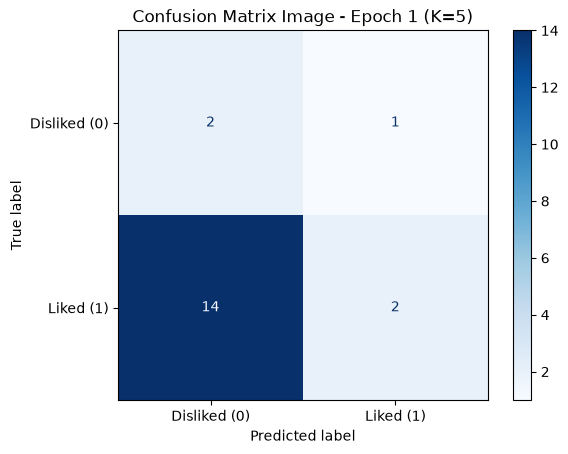

🔄 --- STARTING EPOCH 2/5 (K=10, alpha=0.6) ---
┌────────────────────────────────────────────────────────┐
│ PERFORMANCE EVALUATION LOG - EPOCH 2                   │
├────────────────────────────────────────────────────────┤
│ 📊 Core System Accuracy Metrics:                       │
│  ↳ 1. Recommendation Precision : 66.67 %               │
│  ↳ 2. Recommendation Recall    : 25.0  %               │
│  ↳ 3. Balanced F1-Score        : 36.36 %               │
│                                                        │
│ 🖼️  Generating Graphical Confusion Matrix Window...   │
└────────────────────────────────────────────────────────┘



<Figure size 600x500 with 0 Axes>

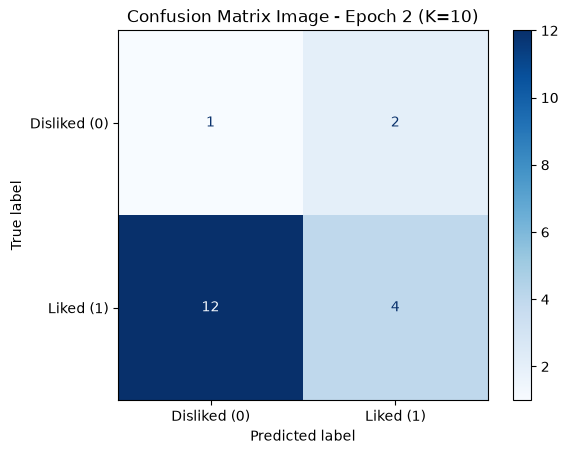

🔄 --- STARTING EPOCH 3/5 (K=15, alpha=0.7) ---
┌────────────────────────────────────────────────────────┐
│ PERFORMANCE EVALUATION LOG - EPOCH 3                   │
├────────────────────────────────────────────────────────┤
│ 📊 Core System Accuracy Metrics:                       │
│  ↳ 1. Recommendation Precision : 75.0  %               │
│  ↳ 2. Recommendation Recall    : 37.5  %               │
│  ↳ 3. Balanced F1-Score        : 50.0  %               │
│                                                        │
│ 🖼️  Generating Graphical Confusion Matrix Window...   │
└────────────────────────────────────────────────────────┘



<Figure size 600x500 with 0 Axes>

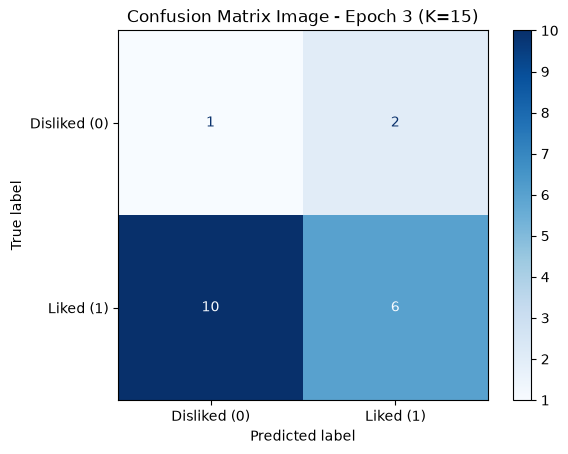

🔄 --- STARTING EPOCH 4/5 (K=20, alpha=0.8) ---
┌────────────────────────────────────────────────────────┐
│ PERFORMANCE EVALUATION LOG - EPOCH 4                   │
├────────────────────────────────────────────────────────┤
│ 📊 Core System Accuracy Metrics:                       │
│  ↳ 1. Recommendation Precision : 75.0  %               │
│  ↳ 2. Recommendation Recall    : 37.5  %               │
│  ↳ 3. Balanced F1-Score        : 50.0  %               │
│                                                        │
│ 🖼️  Generating Graphical Confusion Matrix Window...   │
└────────────────────────────────────────────────────────┘



<Figure size 600x500 with 0 Axes>

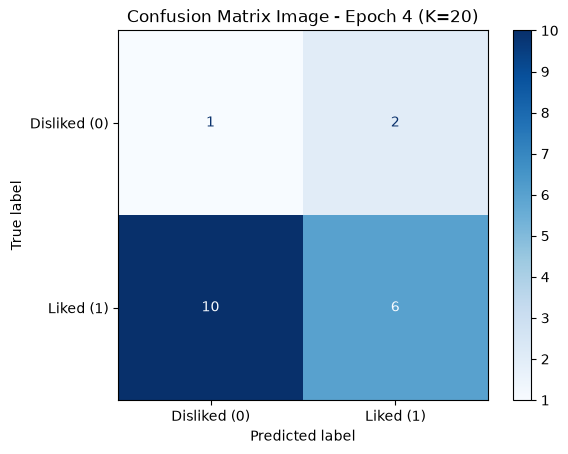

🔄 --- STARTING EPOCH 5/5 (K=25, alpha=0.9) ---
┌────────────────────────────────────────────────────────┐
│ PERFORMANCE EVALUATION LOG - EPOCH 5                   │
├────────────────────────────────────────────────────────┤
│ 📊 Core System Accuracy Metrics:                       │
│  ↳ 1. Recommendation Precision : 80.0  %               │
│  ↳ 2. Recommendation Recall    : 25.0  %               │
│  ↳ 3. Balanced F1-Score        : 38.1  %               │
│                                                        │
│ 🖼️  Generating Graphical Confusion Matrix Window...   │
└────────────────────────────────────────────────────────┘

💾 Saved high-resolution image to asset path: 'final_confusion_matrix.png'



<Figure size 600x500 with 0 Axes>

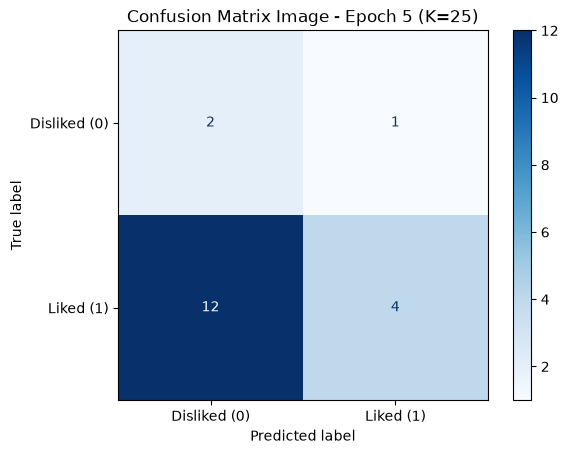

🎯 Testing loop complete. Visual graphs rendered successfully.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sqlalchemy import create_engine
from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ==========================================================
# 1. FETCH LIVE DATA FROM DATABASE
# ==========================================================
engine = create_engine("mysql+mysqlconnector://root:@localhost/plantmatch_db")

with engine.connect() as conn:
    feedback_df = pd.read_sql("SELECT userID, plantID, rating FROM feedback", conn)
    plant_df = pd.read_sql("SELECT * FROM plantmatch_ultimate_complete", conn)

# Clean up duplicate interaction logs
feedback_df = feedback_df.drop_duplicates(subset=['userID', 'plantID']).reset_index(drop=True)

# Generate Base Content Similarities
columns_to_drop = ['ID', 'Scientific_Name', 'Common_Name', 'Image_URL']
feature_matrix = plant_df.drop(columns=columns_to_drop, errors='ignore')
cosine_sim_array = cosine_similarity(feature_matrix)
content_sim_df = pd.DataFrame(cosine_sim_array, index=plant_df["ID"], columns=plant_df["ID"])


# ==========================================================
# 2. SPLIT DATA UNTUK TRAINING AND TESTING (80/20 Split)
# ==========================================================
print("=======================================================================")
print("             SPLIT DATA UNTUK TRAINING AND TESTING                     ")
print("=======================================================================")
train_feedback, test_feedback = train_test_split(feedback_df, test_size=0.20, random_state=42)

print(f"Total Database Feedback Rows: {len(feedback_df)}")
print(f"✔️ Training Set Size (80%): {len(train_feedback)} interaction records")
print(f"✔️ Testing Set Size  (20%): {len(test_feedback)} interaction records")
print("=======================================================================\n")


# Build Utility Matrix using exclusively the Training Split
utility_matrix_train = train_feedback.pivot_table(
    index='userID', columns='plantID', values='rating', aggfunc='mean'
).fillna(0.0)

# Optimized Hybrid Blending Scorer
def get_hybrid_scores(target_user_id, alpha):
    if target_user_id not in utility_matrix_train.index:
        return pd.Series(0.0, index=plant_df["ID"])
        
    user_ratings = utility_matrix_train.loc[target_user_id]
    
    # Content Pipeline
    liked_plants = user_ratings[user_ratings >= 4].index
    liked_plants = [p for p in liked_plants if p in content_sim_df.columns]
    content_scores = content_sim_df[liked_plants].mean(axis=1) if liked_plants else pd.Series(0.0, index=plant_df["ID"])
        
    # Collaborative Pipeline (KNN Guardrails)
    collab_scores = pd.Series(0.0, index=plant_df["ID"])
    n_neighbors = min(3, len(utility_matrix_train))
    if n_neighbors > 1:
        sparse_features = csr_matrix(utility_matrix_train.values)
        knn = NearestNeighbors(metric='cosine', algorithm='brute', n_neighbors=n_neighbors)
        knn.fit(sparse_features)
        
        user_idx = utility_matrix_train.index.get_loc(target_user_id)
        _, indices = knn.kneighbors(utility_matrix_train.iloc[user_idx].values.reshape(1, -1))
        
        for idx in indices.flatten()[1:]:
            for plant_id, rat in utility_matrix_train.iloc[idx].items():
                if plant_id in collab_scores.index: 
                    collab_scores[plant_id] += rat
            
    if collab_scores.max() != collab_scores.min():
        collab_scores = (collab_scores - collab_scores.min()) / (collab_scores.max() - collab_scores.min())
        
    content_scores = content_scores.reindex(plant_df["ID"], fill_value=0.0)
    collab_scores = collab_scores.reindex(plant_df["ID"], fill_value=0.0)
    
    return (content_scores * alpha) + (collab_scores * (1 - alpha))


# ==========================================================
# 3. ACCURACY TESTING VIA ITERATIVE EPOCHS
# ==========================================================
print("🚀 Starting Hybrid Accuracy Engine Validation Over Epochs...\n")

configs_per_epoch = [
    {"K": 5,  "alpha": 0.5},
    {"K": 10, "alpha": 0.6},
    {"K": 15, "alpha": 0.7},
    {"K": 20, "alpha": 0.8},
    {"K": 25, "alpha": 0.9}
]

# Extract explicit ground truth classes from the Testing Split
test_users_liked = test_feedback[test_feedback['rating'] >= 4].groupby('userID')['plantID'].apply(set).to_dict()
test_users_disliked = test_feedback[test_feedback['rating'] < 4].groupby('userID')['plantID'].apply(set).to_dict()

# Run Through 5 Epochs
for epoch in range(1, 6):
    config = configs_per_epoch[epoch - 1]
    current_K = config["K"]
    current_alpha = config["alpha"]
    
    print(f"🔄 --- STARTING EPOCH {epoch}/5 (K={current_K}, alpha={current_alpha}) ---")
    
    y_true = []
    y_pred = []
    
    for user_id in test_users_liked.keys():
        liked_plants_test = test_users_liked.get(user_id, set())
        disliked_plants_test = test_users_disliked.get(user_id, set())
        
        all_tested_plants = liked_plants_test.union(disliked_plants_test)
        if not all_tested_plants:
            continue
            
        scores = get_hybrid_scores(user_id, current_alpha)
        top_recommendations = set(scores.sort_values(ascending=False).head(current_K).index)
        
        for plant_id in all_tested_plants:
            y_true.append(1 if plant_id in liked_plants_test else 0)
            y_pred.append(1 if plant_id in top_recommendations else 0)
            
    if len(y_true) > 0:
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        tn, fp, fn, tp = cm.ravel()
        
        # Performance Evaluation Metrics
        precision = (tp / (tp + fp)) if (tp + fp) > 0 else 0.0
        recall = (tp / (tp + fn)) if (tp + fn) > 0 else 0.0
        f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        
        # Display Box in Terminal Log
        print("┌────────────────────────────────────────────────────────┐")
        print(f"│ PERFORMANCE EVALUATION LOG - EPOCH {epoch}                   │")
        print("├────────────────────────────────────────────────────────┤")
        print("│ 📊 Core System Accuracy Metrics:                       │")
        print(f"│  ↳ 1. Recommendation Precision : {round(precision * 100, 2):<6}%               │")
        print(f"│  ↳ 2. Recommendation Recall    : {round(recall * 100, 2):<6}%               │")
        print(f"│  ↳ 3. Balanced F1-Score        : {round(f1_score * 100, 2):<6}%               │")
        print("│                                                        │")
        print("│ 🖼️  Generating Graphical Confusion Matrix Window...   │")
        print("└────────────────────────────────────────────────────────┘\n")
        
        # RENDER THE VISUAL CONFUSION MATRIX GRAPHICS
        plt.figure(figsize=(6, 5))
        disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Disliked (0)", "Liked (1)"])
        
        # Use a nice blue/green theme ('Blues', 'viridis', or 'GnBu')
        disp.plot(cmap='Blues', values_format='d')
        plt.title(f"Confusion Matrix Image - Epoch {epoch} (K={current_K})")
        
        # Save image automatically to file path
        if epoch == 5:
            plt.savefig("final_confusion_matrix.png", dpi=300, bbox_inches='tight')
            print("💾 Saved high-resolution image to asset path: 'final_confusion_matrix.png'\n")
            
        # Display visual image on user screen interface
        plt.show()
        plt.close()
        
    else:
        print("⚠️ No valid data matches found for evaluation this epoch.\n")

print("=======================================================================")
print("🎯 Testing loop complete. Visual graphs rendered successfully.")
print("=======================================================================")